In [1]:
# 1. Libraries we need
import numpy as np                 # numpy: for number arrays
import matplotlib.pyplot as plt    # matplotlib: to show images/plots
from tensorflow import keras       # keras: high-level API in TensorFlow
from tensorflow.keras import layers
from sklearn.metrics import confusion_matrix, classification_report


In [2]:
(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step


x_train shape: (60000, 28, 28)
y_train shape: (60000,)
x_test shape: (10000, 28, 28)


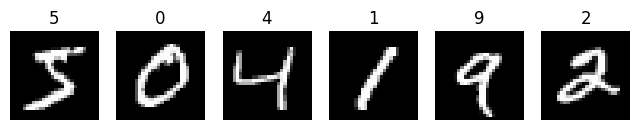

In [3]:
# 3. Look at shapes and draw some examples
print("x_train shape:", x_train.shape)
print("y_train shape:", y_train.shape)
print("x_test shape:", x_test.shape)

# Show the first 6 images with their labels
plt.figure(figsize=(8,2))
for i in range(6):
    plt.subplot(1,6,i+1)
    plt.imshow(x_train[i], cmap='gray')  # show image in gray
    plt.title(str(y_train[i]))
    plt.axis('off')
plt.show()


In [4]:
# 4. Preprocess images
# Convert ints (0-255) to floats (0.0 - 1.0)
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32")  / 255.0

# Add a channel dimension (height, width, channels). For grayscale channels=1
x_train = np.expand_dims(x_train, -1)   # shape becomes (60000, 28, 28, 1)
x_test  = np.expand_dims(x_test, -1)

print("After preprocessing shapes:", x_train.shape, x_test.shape)


After preprocessing shapes: (60000, 28, 28, 1) (10000, 28, 28, 1)


In [5]:
print("Example labels:", y_train[:10])

Example labels: [5 0 4 1 9 2 1 3 1 4]


In [6]:
# 6. Create a validation split from training data
from sklearn.model_selection import train_test_split

x_train_sub, x_val, y_train_sub, y_val = train_test_split(
    x_train, y_train, test_size=0.1, random_state=42)

print("Train now:", x_train_sub.shape, "Validation:", x_val.shape)


Train now: (54000, 28, 28, 1) Validation: (6000, 28, 28, 1)


In [7]:
# 7. Build a simple CNN
model = keras.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    layers.MaxPooling2D((2,2)),
    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D((2,2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(10, activation='softmax')  # 10 outputs for digits 0-9
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()


C:\Users\manha\OneDrive\Documents\CodeAlpha_HandwrittenRecognition\venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 26, 26, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 13, 13, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 11, 11, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 5, 5, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten (Flatten)                    │ (None, 1600)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 128)                 │         204,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │           1,290 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
# 8. Train model
history = model.fit(
    x_train_sub, y_train_sub,
    epochs=5,
    batch_size=64,
    validation_data=(x_val, y_val)
)


Epoch 1/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 18s 17ms/step - accuracy: 0.9504 - loss: 0.1643 - val_accuracy: 0.9802 - val_loss: 0.0637
Epoch 2/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9844 - loss: 0.0494 - val_accuracy: 0.9853 - val_loss: 0.0491
Epoch 3/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 13s 16ms/step - accuracy: 0.9891 - loss: 0.0346 - val_accuracy: 0.9888 - val_loss: 0.0400
Epoch 4/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9919 - loss: 0.0243 - val_accuracy: 0.9870 - val_loss: 0.0431
Epoch 5/5
844/844 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.9930 - loss: 0.0211 - val_accuracy: 0.9882 - val_loss: 0.0399


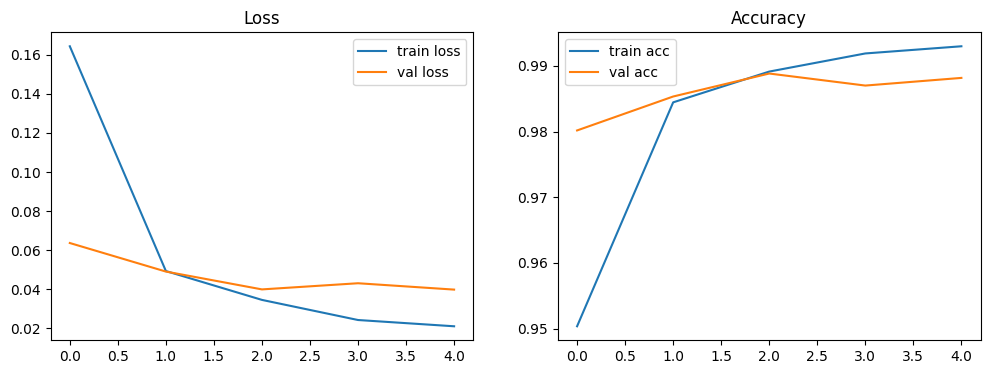

In [9]:
# 9. Plot training curves
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.title('Loss')

plt.subplot(1,2,2)
plt.plot(history.history['accuracy'], label='train acc')
plt.plot(history.history['val_accuracy'], label='val acc')
plt.legend()
plt.title('Accuracy')
plt.show()


In [10]:
# 10. Final evaluation on test set
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print("Test accuracy:", test_acc)


313/313 - 2s - 7ms/step - accuracy: 0.9897 - loss: 0.0359
Test accuracy: 0.9897000193595886


313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 6ms/step
Classification report:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99       980
           1       0.99      1.00      0.99      1135
           2       0.99      0.99      0.99      1032
           3       0.98      1.00      0.99      1010
           4       0.99      0.99      0.99       982
           5       0.99      0.98      0.99       892
           6       0.99      0.99      0.99       958
           7       0.98      1.00      0.99      1028
           8       0.99      0.99      0.99       974
           9       0.99      0.97      0.98      1009

    accuracy                           0.99     10000
   macro avg       0.99      0.99      0.99     10000
weighted avg       0.99      0.99      0.99     10000

Confusion matrix shape: (10, 10)


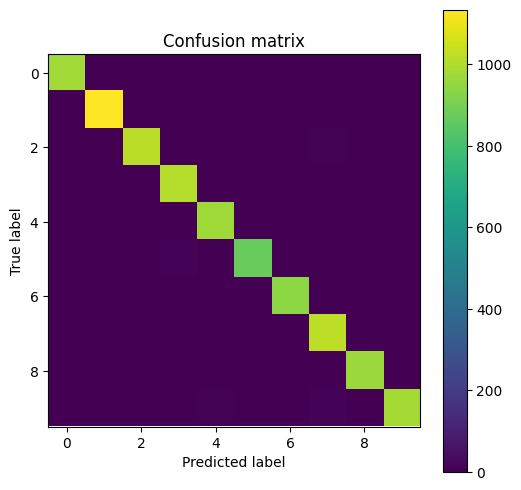

In [11]:
# 11. Predictions and confusion matrix
y_pred_probs = model.predict(x_test)          # probabilities shape (10000,10)
y_pred = np.argmax(y_pred_probs, axis=1)      # pick highest prob as predicted class

# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
print("Classification report:\n", classification_report(y_test, y_pred))
print("Confusion matrix shape:", cm.shape)

# Show the confusion matrix as an image
plt.figure(figsize=(6,6))
plt.imshow(cm, interpolation='nearest')
plt.colorbar()
plt.title('Confusion matrix')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()


In [12]:
# 12. Save model
model.save('models/mnist_cnn.h5')   # saved in models/ folder


In [13]:
layers.Dropout(0.5)


<Dropout name=dropout, built=True>

In [14]:
import tensorflow_datasets as tfds
ds_train = tfds.load('emnist/letters', split='train', as_supervised=True)


C:\Users\manha\OneDrive\Documents\CodeAlpha_HandwrittenRecognition\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
Dl Completed...: 0 url [00:00, ? url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Completed...:   0%|                                                                         | 0/1 [00:00<?, ? url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Size...:   0%|                                                                            | 0/535 [00:02<?, ? MiB/s]

Extraction completed...: 0 file [00:02, ? file/s]
Dl Size...:   0%|▏                                                                   | 1/535 [00:02<25:56,  2.92s/ MiB]

Dl Size...:   0%|▎                                                                   | 2/535 [00:03<25:53,  2.92s/ MiB]

Dl Size...:   1%|▍                                          

Dataset emnist downloaded and prepared to C:\Users\manha\tensorflow_datasets\emnist\letters\3.1.0. Subsequent calls will reuse this data.
